# EN3160 Assignment 02

## Fitting and Alignment

---

**Name:** R.A.C.D. Ranawaka    
**Index Number:** 230526A  
**GitHub Link:** https://github.com/chaniruranawaka/Fitting-and-Alignment

---

### Q1. Blob Detection

In [145]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from scipy.ndimage import maximum_filter

Image shape: (360, 360, 3)
Gray image shape: (360, 360)


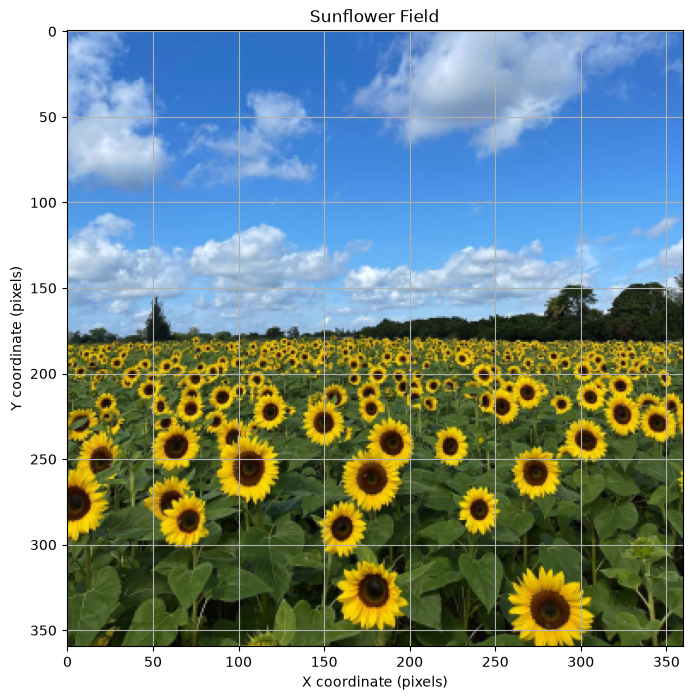

In [146]:
im = cv.imread('C:/Users/chani/OneDrive/Documents/Uni/Semester 5/EN3160 - Image Processing and Machiene Vision/IPMV_A02/a2images/the_berry_farms_sunflower_field.jpeg',
               cv.IMREAD_REDUCED_COLOR_4)

if im is None:
    raise FileNotFoundError("Could not load the sunflowere image.")

im_rgb = cv.cvtColor(im, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY)

print("Image shape:", im.shape)
print("Gray image shape:", gray.shape)

plt.figure(figsize=(14, 8))
plt.imshow(im_rgb)
plt.title("Sunflower Field")
plt.xlabel("X coordinate (pixels)")
plt.ylabel("Y coordinate (pixels)")
plt.grid()
plt.show()

In [147]:
sigma_values = np.arange(1.0, 12.5, 0.5)

In [148]:
gray_float = gray.astype(np.float32) / 255.0

log_responses = []

for sigma in sigma_values:
    # Gaussian smoothing
    blurred = cv.GaussianBlur(gray_float, (0, 0), sigmaX=sigma, sigmaY=sigma)

    # Compute Laplacian
    laplacian = cv.Laplacian(blurred, cv.CV_32F, ksize=3)

    response = (sigma ** 2) * np.abs(laplacian)
    log_responses.append(response)

log_responses = np.stack(log_responses, axis=0)

print("Scale space shape:", log_responses.shape)

Scale space shape: (23, 360, 360)


In [149]:
# Find local maxima in space and scale
local_maxima = (
    log_responses ==
    maximum_filter(log_responses, size=(3, 3, 3))
)

# Exclude the first and last scales because
# they do not have neighbours on both sides in scale
local_maxima[0, :, :] = False
local_maxima[-1, :, :] = False

# Reject extremely weak responses
response_threshold = 0.02

extrema_mask = (
    local_maxima &
    (log_responses > response_threshold)
)

candidate_indices = np.argwhere(extrema_mask)

print("Number of detected extrema:", len(candidate_indices))

Number of detected extrema: 1994


In [150]:
circles = []

for scale_index, y, x in candidate_indices:
    sigma = float(sigma_values[scale_index])
    radius = np.sqrt(2) * sigma

    response_strength = float(log_responses[scale_index, y, x])

    circles.append({
        "x": int(x),
        "y": int(y),
        "sigma": sigma,
        "radius": float(radius),
        "response": response_strength  
    })

print("Total number of detected blobs:", len(circles))

Total number of detected blobs: 1994


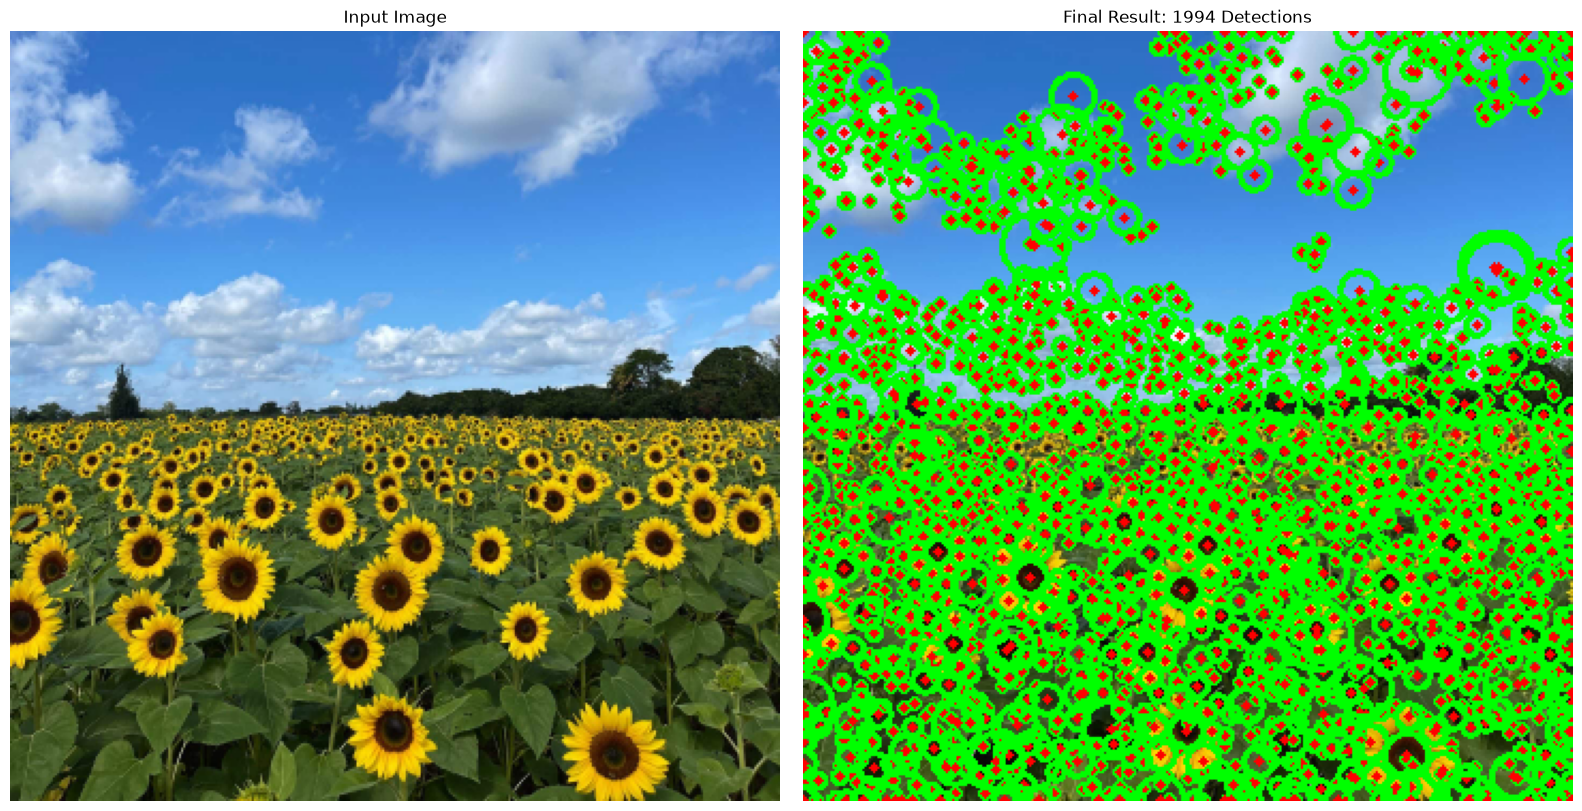

In [151]:
result = im.copy()

for circle in circles:
    center = (circle["x"], circle["y"])
    radius = max(1, int(round(circle["radius"])))

    cv.circle(result, center, radius, (0, 255, 0), 2)
    cv.circle(result, center, 2, (0, 0, 255), -1)  # Draw center point

result_rgb = cv.cvtColor(result, cv.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(im_rgb)
axes[0].set_title("Input Image")
axes[0].axis("off")

axes[1].imshow(result_rgb)
axes[1].set_title(f"Final Result: {len(circles)} Detections")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [152]:
circles_sorted = sorted(
    circles,
    key=lambda circle: circle["radius"],
    reverse=True
)

largest_circles = circles_sorted[:10]

results_df = pd.DataFrame([
    {
        "Rank": i + 1,
        "x": circle["x"],
        "y": circle["y"],
        "Sigma": round(circle["sigma"], 2),
        "Radius (pixels)": round(circle["radius"], 2),
        "Diameter (pixels)": round(2 * circle["radius"], 2),
        "LoG Response": round(circle["response"], 5)
    }
    for i, circle in enumerate(largest_circles)
])

display(results_df)

,Rank,x,y,Sigma,Radius (pixels),Diameter (pixels),LoG Response
0,1,323,110,11.0,15.56,31.11,0.03762
1,2,325,110,11.0,15.56,31.11,0.03785
2,3,240,282,11.0,15.56,31.11,0.58225
3,4,287,19,10.5,14.85,29.70,0.24987
4,5,108,100,10.5,14.85,29.70,0.21975
5,6,324,112,10.5,14.85,29.70,0.03738
6,7,334,305,10.5,14.85,29.70,0.35165
7,8,107,73,10.0,14.14,28.28,0.23899
8,9,0,315,10.0,14.14,28.28,0.22299
9,10,121,48,9.5,13.44,26.87,0.56797


In [153]:
print(f"Sigma range used: {sigma_values.min():.1f} to {sigma_values.max():.1f}")

detected_sigmas = sorted({
    circle["sigma"] for circle in circles
})

print("Detected sigma values:", detected_sigmas)

Sigma range used: 1.0 to 12.0
Detected sigma values: [1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 10.0, 10.5, 11.0]
